<h1>Deteksi Emosi dengan Suara Manusia</h1>

<h2>Tentang Data</h2>
<p>Proyek ini menggunakan dataset dari Ryerson Audio-Visual Database of Emotional Speech and Song (RAVDESS) Emotional Speech Audio (https://doi.org/10.1371/journal.pone.0196391).</p>
<p>Dalam dataset ini, terdapat <b>1440 file audio (.wav)</b> yang berisi percobaan audio dari 24 aktor (12 laki-laki & 12 perempuan) dengan masing-masing aktor melakukan 60 percobaan pada dua kalimat menggunakan aksen Amerika Utara yang netral. Berikut penamaan file beserta penjelasannya: (Contoh: 03-01-06-01-02-01-12.wav)</p>
<li><b>Modality</b> (01 = full-AV, 02 = video-only, 03 = audio-only)</li>
<li><b>Vocal channel</b> (01 = speech, 02 = song)</li>
<li><b>Emotion</b> (01 = neutral, 02 = calm, 03 = happy, 04 = sad, 05 = angry, 06 = fearful, 07 = disgust, 08 = surprised)</li>
<li><b>Emotional intensity</b> (01 = normal, 02 = strong). NOTE: There is no strong intensity for the 'neutral' emotion</li>
<li><b>Statement</b> (01 = "Kids are talking by the door", 02 = "Dogs are sitting by the door")</li>
<li><b>Repetition</b> (01 = 1st repetition, 02 = 2nd repetition)</li>
<li><b>Actor</b> (01 to 24. Ganjil: laki-laki, Genap: perempuan)</li>

In [1]:
import os
import zipfile
import random
import librosa
import librosa.display
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import IPython.display as ipd

from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import warnings
warnings.filterwarnings("ignore")

<h2>Mengekstrak zip file (tidak perlu dijalankan lagi)</h2>
<p>Data yang telah diunduh dalam bentuk zip akan diekstrak dan dibaca</p>

In [3]:
# Mengekstrak file
zip_path = "./archive.zip"         
extract_path = "./archive"        

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Done extracting!")

✅ Done extracting!


<h2>Data Preprocessing</h2>
<p>Untuk meningkatkan akurasi dalam mendeteksi emosi dari suara manusia, dilakukan pembersihan data sehingga dari 1440 audio, dipilih audio dengan modality = audio-only, vocal channel = speech, dan intensitas = strong. Dengan demikian, jumlah file yang digunakan adalah <b>672 audio</b>.</p>
<p>Ekstraksi fitur dilakukan menggunakan <b>Mel-Frequency Cepstral Coefficients (MFCC)</b>, karena skala Mel mampu meniru persepsi pendengaran manusia. MFCC efektif dalam menangkap perbedaan emosi yang tercermin melalui intonasi, nada, dan kecepatan bicara. Selain itu, penggunaan Discrete Cosine Transform (DCT) dalam MFCC membantu mereduksi dimensi data tanpa menghilangkan informasi penting.</p>
<p><b>Cara kerja MFCC:</b></p>
<ol> <li><b>Analog to Digital Converter</b><br>Sampling - Quantizing - Coding<br> </li><li><b>Framing</b><br> Sinyal dibagi menjadi potongan kecil (misalnya 25 ms per frame) agar dianggap stasioner.<br> <i>Contoh: 1 detik audio dibagi menjadi 40 frame jika frame size = 25 ms dan overlap = 10 ms.</i> </li> <li><b>Windowing</b><br> Tiap frame dikalikan dengan <b>Hamming Window</b> untuk mengurangi diskontinuitas di ujung frame.<br> <i>Tujuan: menghindari artefak spektral saat FFT.</i> </li> <li><b>Fast Fourier Transform (FFT)</b><br> Mengubah sinyal dari domain waktu ke domain frekuensi.<br> <i>Output: spektrum amplitudo atau daya dari tiap frame.</i> </li> <li><b>Mel Filter Bank</b><br> Spektrum dilewatkan ke serangkaian filter segitiga dalam skala Mel yang meniru persepsi pendengaran manusia.<br>Filter lebih rapat di frekuensi rendah, lebih jarang di frekuensi tinggi.<br>Karena telinga manusia sangat sensitif dengan frekuensi rendah (300Hz) dan kurang sensitif dengan frekuensi tinggi (8000Hz) </li> <li><b>Log Energi</b><br> Energi dari masing-masing filter diubah menjadi skala logaritmik.<br> <i>Tujuan: mencerminkan persepsi manusia terhadap intensitas suara.</i> <br> Telinga manusia akan merasakan kenaikan volume besar pada amplitudo rendah dan kenaikan volume kecil pada amplitudo tinggi.</li> <li><b>Discrete Cosine Transform (DCT)</b><br> Reduksi dimensi dan mengambil 13 koefisien pertama.<br> <i>Tujuan: mengurangi korelasi antar fitur dan merangkum energi dominan.</i> </li> <li><b>Delta</b><br> Mengukur perubahan nilai MFCC antar frame → mencerminkan kecepatan perubahan suara.<br><i>Tujuan: Menangkap dinamika suara</i> </li> <li><b>Delta-Delta</b><br> Mengukur perubahan dari delta → mencerminkan percepatan perubahan suara.<br> <i>Tujuan: Menangkap dinamika suara</i> </li> <li><b>Pitch (f0)</b><br> Frekuensi dasar dari getaran pita suara. <br> Pitch tinggi sering dikaitkan dengan emosi seperti marah atau takut. <br> Pitch rendah dikaitkan dengan emosi tenang atau sedih </li> <li><b>Spectral Contrast</b><br> Mengukur perbedaan energi antara puncak (peak) dan lembah (valley) pada spektrum frekuensi.<br> <i>Berfungsi membedakan jenis emosi berdasarkan kontur spektral.</i> <br> Frekuensi rendah menandakan suara datar (sedih) dan frekuensi tinggi menandakan suara tajam (marah)</li> <li><b>Loudness</b><br> Mengukur intensitas relatif atau kekerasan suara berdasarkan persepsi manusia. <br> Amplitudo rendah menandakan volume lembut (sedih) dan amplitudo tinggi menandakan volume keras (marah)</li> </ol>

In [4]:
def extract_features(file_path):
    y, sr = librosa.load(file_path, sr=16000)

    # Menghapus bagian senyap dari awal dan akhir file
    y, _ = librosa.effects.trim(y, top_db=20)

    # Mengisi 0 pada bagian NaN
    if len(y) == 0:
        y = np.zeros(1)  

    # Ekstrak 13 koefisien MFCC dari 40 filter bank Mel
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, n_mels=40)

    # Turunan pertama dan turunan kedua dari MFCC
    delta_mfccs = librosa.feature.delta(mfccs)
    delta2_mfccs = librosa.feature.delta(mfccs, order=2)

    # Pmenghitung pitch dari suara manusia dan mengisi NaN dengan rata-rata
    f0, _, _ = librosa.pyin(y, fmin=80, fmax=400)
    f0_mean = np.nanmean(f0) if np.any(~np.isnan(f0)) else 0.0

    # Spectral contrast: menghitung perbedaan frekuensi
    contrast = librosa.feature.spectral_contrast(y=y, sr=sr)

    # Loudness: Menghitung perbedaan amplitudo
    S = np.abs(librosa.stft(y))
    if np.any(S == 0):
        S = np.clip(S, a_min=1e-10, a_max=None)  # Avoid log(0)
    loudness = np.mean(librosa.amplitude_to_db(S, ref=np.max))

    # Dabungkan semua fitur
    features = np.concatenate([
        np.mean(mfccs, axis=1),
        np.std(mfccs, axis=1),
        np.mean(delta_mfccs, axis=1),
        np.mean(delta2_mfccs, axis=1),
        [f0_mean],
        np.mean(contrast, axis=1),
        [loudness]
    ])

    return np.nan_to_num(features, nan=0.0)

In [20]:
# Mengekstrak Fitur dengan MFCC
DATA_PATH = "./archive/audio_speech_actors_01-24"
features = []
filtered_files = []

emotion_dict = {
    '01': 'neutral', '02': 'calm', '03': 'happy', '04': 'sad',
    '05': 'angry', '06': 'fearful', '07': 'disgust', '08': 'surprised'
}

for root, _, files in os.walk(DATA_PATH):
    for file in files:
        if file.endswith(".wav"):
            parts = file.split("-")
            if len(parts) >= 4:
                modality = parts[0]
                vocal_channel = parts[1]
                intensity = parts[3]

                if intensity == '02':
                    emotion_code = parts[2]
                    emotion = emotion_dict.get(emotion_code)
                    if emotion:
                        path = os.path.join(root, file)
                        try:
                            data = extract_features(path)
                            features.append([data, emotion])
                            filtered_files.append(path)
                        except Exception as e:
                            print(f"⚠️ Error processing {file}: {e}")

# Melihat bentuk data pada DataFrame
df = pd.DataFrame(features, columns=["feature", "emotion"])
print(df.head())
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

                                             feature emotion
0  [-279.12518310546875, 72.1197738647461, 9.0601...    calm
1  [-277.1251525878906, 66.58549499511719, 6.8225...    calm
2  [-267.82196044921875, 63.15345764160156, 11.82...    calm
3  [-257.1549987792969, 62.64823532104492, 8.6100...    calm
4  [-185.64675903320312, 56.18682098388672, -2.82...   happy
Number of rows: 672
Number of columns: 2


<h3>Hasil Preprocessing</h3>
<p>Terdiri dari 61 kolom:</p>
<ol>
    <li>MFCC mean (13 kolom)</li>
    <li>MFCC Std dev (13 kolom)</li>
    <li>Delta MFCC (13 kolom)</li>
    <li>Delta-delta MFCC (13 kolom)</li>
    <li>Pitch (1 kolom)</li>
    <li>Spectral Contrast (7 kolom)</li>
    <li>Loudness (1 kolom)</li>
    <li>Target: Emotion</li>
</ol>

<h3>Melihat ke dalam MFCC, Delta, dan Delta-Delta</h3>

In [23]:
random_audio_file = random.choice(filtered_files)
print(f"\nPlaying: {random_audio_file}")
ipd.display(ipd.Audio(random_audio_file))


▶️ Playing: ./archive\audio_speech_actors_01-24\Actor_16\03-01-04-02-01-02-16.wav


Amount of samples: (60861,)
MFCC shape: (13, 119)


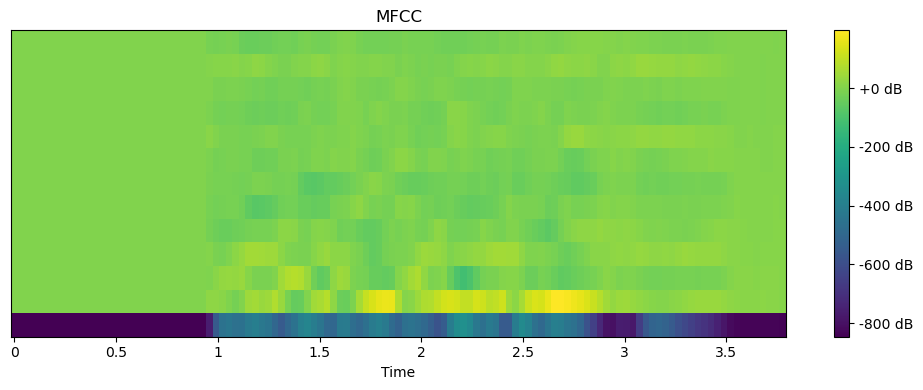

In [24]:
# MFCC
signal, sr = librosa.load(random_audio_file, sr=16000)
print(f'Amount of samples: {signal.shape}')
    
mfccs = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=13)
print(f'MFCC shape: {mfccs.shape}')

plt.figure(figsize=(10, 4))
librosa.display.specshow(mfccs, x_axis='time', sr=sr, cmap='viridis')
plt.colorbar(format='%+2.0f dB')
plt.title('MFCC')
plt.tight_layout()
plt.show()

Delta MFCC shape: (13, 119)
Delta2 MFCC shape: (13, 119)


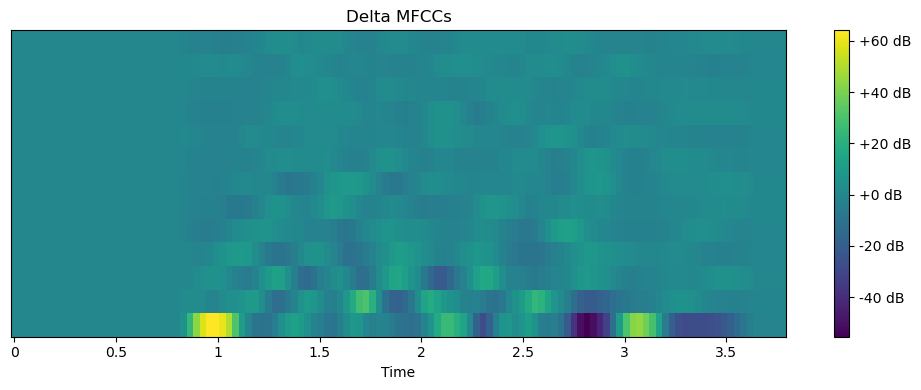

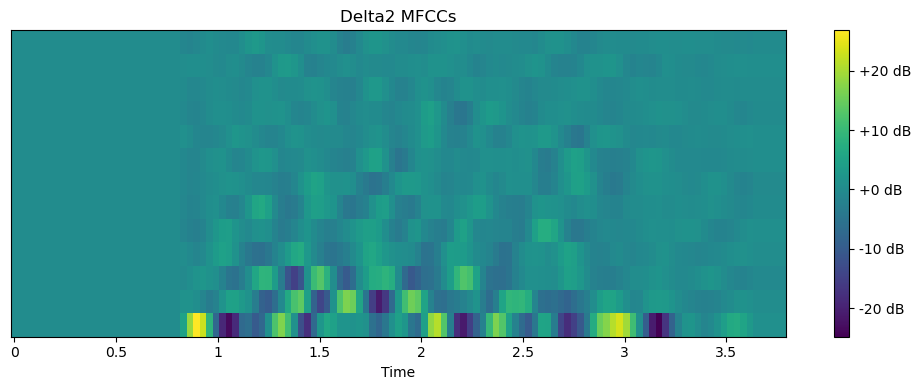

In [25]:
# Delta dan Delta2 MFCC
delta_mfccs = librosa.feature.delta(mfccs)
delta2_mfccs = librosa.feature.delta(mfccs, order=2)

print(f'Delta MFCC shape: {delta_mfccs.shape}')
print(f'Delta2 MFCC shape: {delta2_mfccs.shape}')

plt.figure(figsize=(10, 4))
librosa.display.specshow(delta_mfccs, x_axis='time', sr=sr, cmap='viridis')
plt.colorbar(format='%+2.0f dB')
plt.title('Delta MFCCs')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
librosa.display.specshow(delta2_mfccs, x_axis='time', sr=sr, cmap='viridis')
plt.colorbar(format='%+2.0f dB')
plt.title('Delta2 MFCCs')
plt.tight_layout()
plt.show()

<h2>Model Tuning</h2>
<p>Fitur-fitur Dataset akan dilatih untuk menghasilkan model yang dalam mengklasifikasi emosi dengan Support Vector Machine (SVM) dan StratifiedKFold dengan k = 5. Pelatihan dilakukan dengan GridsearchCV:</p>
<li>'svm__C':[0.1, 1, 10, 100]</li>
<li>'svm__gamma': [0.001, 0.01, 0.1, 1]</li>
<br>
<p><b>Cara kerja SVM:</b></p>
<ol> <li><strong>Memisahkan data dengan garis batas (hyperplane):</strong><br> SVM bekerja dengan mencari sebuah garis (untuk data 2D) atau hyperplane (untuk data berdimensi lebih tinggi) yang memisahkan kelas-kelas data secara optimal. </li> <li><strong>Maksimalkan margin antar kelas:</strong><br> SVM tidak hanya mencari garis pemisah, tapi juga yang memberi jarak (margin) maksimum antara data dua kelas yang paling dekat dengan garis tersebut. Data yang paling dekat ini disebut <i>support vectors</i>. </li> <li><strong>Menggunakan kernel karena data tidak bisa dipisahkan secara linear:</strong><br> SVM menggunakan fungsi <i>kernel</i>: Gaussian Radial Basis Function untuk mengubah data ke dimensi yang lebih tinggi agar bisa dipisahkan. </li> <li><strong>Menentukan keputusan berdasarkan posisi relatif terhadap hyperplane:</strong><br> Setelah model dilatih, data baru diklasifikasikan berdasarkan apakah ia berada di sisi kiri atau kanan dari hyperplane (atau di atas/bawah tergantung dimensi). </li> <li><strong>Hanya support vectors yang berpengaruh pada model akhir:</strong><br> SVM hanya memperhatikan data yang dekat dengan hyperplane, jadi data yang jauh tidak memengaruhi garis keputusan. </li> <li><strong>Parameter penting:</strong><br> <ul> <li>C: Mengontrol trade-off antara kesalahan klasifikasi di training dan margin maksimum. C besar → model lebih ketat.</li> <li>gamma: Seberapa jauh pengaruh satu titik data dalam kernel RBF. Gamma kecil → pengaruh lebih lebar/global.</li> </ul> </li> </ol>

In [22]:
# Persiapan Fitur dan Label
X = np.vstack(df["feature"]) 
y = df["emotion"]

# Encoding Label
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

# Membuat pipeline untuk menormalkan fitur dan membuat model SVM
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', class_weight='balanced'))
])

# Grid Search untuk Tuning Hyperparameters
param_grid = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': [0.001, 0.01, 0.1, 1]
}

# Stratified K-Fold Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring='accuracy', verbose=1, n_jobs=-1)
grid.fit(X_train, y_train)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svm', SVC(class_weight='balanced'))]),
             n_jobs=-1,
             param_grid={'svm__C': [0.1, 1, 10, 100],
                         'svm__gamma': [0.001, 0.01, 0.1, 1]},
             scoring='accuracy', verbose=1)

<h2>Evaluasi Model</h2>


Best Parameters: {'svm__C': 10, 'svm__gamma': 0.01}
Best CV Accuracy: 0.7635
Test Accuracy: 0.8000


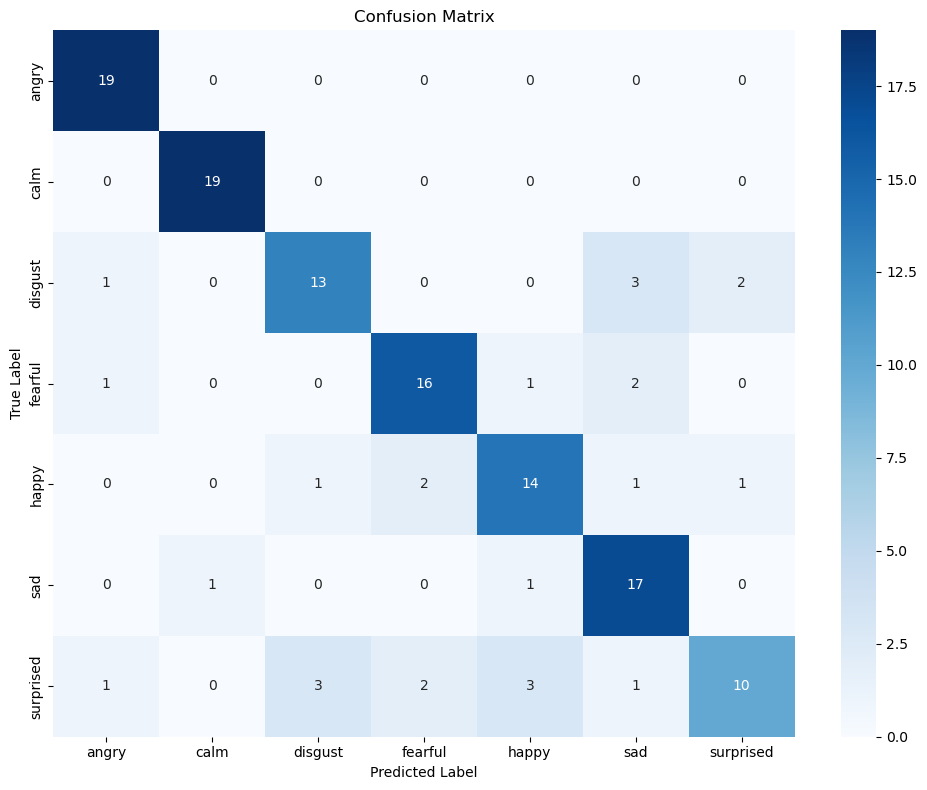

Classification Report
              precision    recall  f1-score   support

       angry       0.86      1.00      0.93        19
        calm       0.95      1.00      0.97        19
     disgust       0.76      0.68      0.72        19
     fearful       0.80      0.80      0.80        20
       happy       0.74      0.74      0.74        19
         sad       0.71      0.89      0.79        19
   surprised       0.77      0.50      0.61        20

    accuracy                           0.80       135
   macro avg       0.80      0.80      0.79       135
weighted avg       0.80      0.80      0.79       135

Akurasi untuk emosi 'angry': 1.0
Akurasi untuk emosi 'calm': 1.0
Akurasi untuk emosi 'disgust': 0.6842105263157895
Akurasi untuk emosi 'fearful': 0.8
Akurasi untuk emosi 'happy': 0.7368421052631579
Akurasi untuk emosi 'sad': 0.8947368421052632
Akurasi untuk emosi 'surprised': 0.5


In [24]:
# Parameter terbaik
print(f"\nBest Parameters: {grid.best_params_}")
print(f"Best CV Accuracy: {grid.best_score_:.4f}")

# Evaluasi Test Dataset
y_pred = grid.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {test_acc:.4f}")

# Confusion Matrix
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=le.classes_,
            yticklabels=le.classes_,
            cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

# Evaluasi per Emosi
print('Classification Report')
report = classification_report(y_test, y_pred, target_names=le.classes_)
print(report)

y_test = np.array(y_test)
y_pred = np.array(y_pred)

for i, class_name in enumerate(le.classes_):
    idx = y_test == i
    acc = np.mean(y_pred[idx] == y_test[idx])
    print(f"Akurasi untuk emosi '{class_name}': {acc}")

<h3><b>Kesimpulan</b></h3>

<p><b>Best Parameter:</b></p>
<li>svm_c: 10</li>
<li>svm_gamma: 0.01</li>
<br>
<p><b>Best CV Accuracy</b> adalah 76,35% dan <br> <b>Test Accuracy</b> adalah 80%. <br>Hal ini menandakan bahwa tidak terjadi overfitting.<p><br> 
<b>Perbandingan:</b>
<br> Akurasi pada Makalah M. Jain, S. Narayan, P. Balaji, A. Bhowmick, R.K. Muthu, et al. (2020): 85,085%
<br> Akurasi pada Makalah A. Milton, S.S. Roy, S.T. Selvi (2013): 55,4%

<br>
<p>Dengan dukungan makalah-makalah tersebut, dapat dilihat bahwa model yang dihasilkan dalam proyek ini cukup untuk mendeteksi emosi manusia melalui audio dan dapat dikembangkan lebih lanjut untuk meningkatkan akurasi prediksi pada emosi-emosi manusia dengan mencoba menggunakan kernel-kernel maupun model yang lain. </p>